# Прогнозирование времени доставки в сервисе еды

In [1]:
import os
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sqlalchemy import create_engine
import mlflow
from tqdm import tqdm
from typing import Dict, Tuple

import warnings
warnings.filterwarnings("ignore", category=UserWarning)

import logging
logging.getLogger("mlflow").setLevel(logging.ERROR)

# Подключение через SQLAlchemy
engine = create_engine(f"sqlite:///{"delivery_final_homework.db"}")

In [2]:
# Проверяем: выводим список таблиц
tables = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table';", engine)
print("\n📊 Доступные таблицы в БД:")
for i, table in enumerate(tables['name'], 1):
    print(f"  {i}. {table}")


📊 Доступные таблицы в БД:
  1. customers
  2. couriers
  3. restaurants
  4. weather
  5. traffic
  6. orders


## 📊 Описание данных

База данных содержит **6 таблиц**, которые отражают разные аспекты работы сервиса доставки:

## 1. 👥 customers — информация о клиентах
- `customer_id` — уникальный идентификатор клиента
- `customer_city` — город регистрации клиента (город может не соответсвовать текущему месту проживания)
- `account_age_days` — сколько дней клиент пользуется сервисом
- `preferred_payment_method` — предпочтительный способ оплаты (card/cash/sbp)
- `mobile_os` — операционная система смартфона (iOS/Android)
- `registration_date` — дата регистрации
- `customer_rating` — рейтинг клиента (как часто жалуется и т.д.)

## 2. 🚴 couriers — информация о курьерах
- `courier_id` — уникальный идентификатор курьера
- `vehicle_type` — тип транспорта (bike/car/scooter)
- `experience_days` — стаж работы в днях
- `base_skill` — базовый навык вождения
- `start_date` — дата начала работы
- `base_speed_kmh` — базовая скорость (км/ч)
- `courier_rating` — рейтинг курьера
- `on_time_ratio` — доля своевременных доставок

## 3. 🍔 restaurants — информация о ресторанах
- `restaurant_id` — уникальный идентификатор ресторана
- `restaurant_city` — город ресторана
- `cuisine_type` — тип кухни (italian/asian/russian/burger)
- `is_fast_food` — флаг быстрого питания (1) или ресторана (0)
- `open_date` — дата открытия
- `restaurant_rating` — рейтинг ресторана
- `prep_time_avg` — среднее время приготовления (минуты)

## 4. 🌦 weather — погодные условия (по дням и городам)
- `date` — дата
- `city` — город
- `temperature` — температура (°C)
- `precip_mm` — количество осадков (мм)
- `wind_speed` — скорость ветра (м/с)

## 5. 🚗 traffic — данные о трафике (по дням и городам)
- `date` — дата
- `city` — город
- `traffic_level` — уровень загруженности дорог (1-5)
- `is_rush_hour` — флаг часа пик

## 6. 📦 orders — заказы (целевая таблица)
- `order_id` — уникальный идентификатор заказа
- `order_datetime` — дата и время заказа
- `customer_id` — ID клиента
- `courier_id` — ID курьера
- `restaurant_id` — ID ресторана
- `order_amount` — сумма заказа (₽)
- `items_count` — количество позиций
- `distance_km` — расстояние от ресторана до клиента (км)
- `is_express_delivery` — флаг экспресс-доставки
- **`delivery_time_minutes`** — время доставки (минуты)
- `payment_method` — фактический способ оплаты

## 🏗️ Этап 1: Загрузка данных (DWH)

In [87]:
# orders + customers + couriers + restaurants
orders = pd.read_sql("""
SELECT 
    o.*, DATE(o.order_datetime) as order_date, 
    c.account_age_days, c.preferred_payment_method, c.mobile_os, c.registration_date, c.customer_rating,
    cu.vehicle_type, cu.experience_days, cu.base_skill, cu.start_date, cu.base_speed_kmh, cu.courier_rating, cu.on_time_ratio,
    r.restaurant_city, r.cuisine_type, r.is_fast_food, r.open_date, r.restaurant_rating, r.prep_time_avg,
    w.temperature, w.precip_mm, w.wind_speed, 
    t.traffic_level, t.is_rush_hour
    FROM orders o
    LEFT JOIN customers c ON c.customer_id = o.customer_id
    LEFT JOIN couriers cu ON cu.courier_id = o.courier_id
    LEFT JOIN restaurants r ON r.restaurant_id = o.restaurant_id
    LEFT JOIN weather w ON DATE(o.order_datetime) = w.date AND w.city = r.restaurant_city
    LEFT JOIN traffic t ON DATE(o.order_datetime) = t.date AND t.city = r.restaurant_city
    """, engine)

## 2. Заполнение пропусков

In [88]:
orders.isnull().sum()

order_id                       0
order_datetime                 0
customer_id                    0
courier_id                     0
restaurant_id                  0
order_amount                   0
items_count                    0
distance_km                    0
is_express_delivery            0
delivery_time_minutes          0
payment_method                 0
order_date                     0
account_age_days               0
preferred_payment_method       0
mobile_os                      0
registration_date              0
customer_rating                0
vehicle_type                   0
experience_days                0
base_skill                     0
start_date                     0
base_speed_kmh                 0
courier_rating                 0
on_time_ratio                  0
restaurant_city                0
cuisine_type                   0
is_fast_food                   0
open_date                      0
restaurant_rating              0
prep_time_avg                  0
temperatur

In [89]:
orders['order_datetime'] = pd.to_datetime(orders['order_datetime'])
orders['order_date'] = pd.to_datetime(orders['order_date'])
orders['traffic_level'] = orders['traffic_level'].apply(lambda x: str(x))

# Пропущенные значения температуры, осадков и скорости ветра заполним средним по месяцу
def weather_conditions_monthly(column_name):
    new_column = orders.groupby(['restaurant_city', orders['order_date'].dt.month])[column_name].transform(lambda x: x.fillna(x.mean()))
    return new_column
    
for col in ['temperature', 'precip_mm', 'wind_speed']:
    orders[col] = weather_conditions_monthly(col)

In [91]:
# traffic level возьмем как среднее по часу заказа и дню недели и городу
orders['traffic_level'] = (
    orders.groupby(['restaurant_city', orders['order_datetime'].dt.hour, orders['order_date'].dt.dayofweek])['traffic_level']
          .transform(lambda x: x.fillna(x.mode()[0])) # Самое часто встречающееся значение
)

In [93]:
# Проверка на оставшиеся значения
orders[['temperature', 'precip_mm', 'wind_speed', 'traffic_level']].isnull().sum()

temperature      0
precip_mm        0
wind_speed       0
traffic_level    0
dtype: int64

## 3. Удаление признаков

In [94]:
# проверка на наличие дубликатов
duplicates = orders.duplicated(subset=['order_id']).sum()
print(f'Найдено дубликатов: {duplicates}')

Найдено дубликатов: 0


In [95]:
print('Количество пользователей:', orders['customer_id'].nunique(), '\n',
      'Количество курьеров:', orders['courier_id'].nunique(), '\n',
     'Количество ресторанов:', orders['restaurant_id'].nunique())

Количество пользователей: 43185 
 Количество курьеров: 400 
 Количество ресторанов: 300


1. id заказов и id клиентов нам не нужны -> клиентов много, и заказывать еду они могут не всегда в одно и то же место
2. id курьеров также не нужны - они могут со временем меняться, и их на данный момент 400
3. То же касается и ресторанов
4. registration_date не нужна, т.к. есть количество дней, сколько клиент пользуется сервисом
5. У курьеров удалим start_date -> важнее количество фактически отработанных дней (признак experience_days)

In [96]:
cols_to_drop = ['customer_id', 'courier_id', 'restaurant_id', 'registration_date', 'start_date']
orders = orders.drop(cols_to_drop, axis=1)

## 4. Создание дополнительных признаков

In [97]:
# 1. - Время работы ресторана в днях
orders['open_date'] = pd.to_datetime(orders['open_date'])
orders['order_datetime'] = pd.to_datetime(orders['order_datetime'])
orders['restaurant_work_days'] = (orders['order_date'] - orders['open_date']).dt.days  

In [98]:
# 2. Нагрузка на ресторан - сколько заказов в этот час и день недели в среднем бывает
orders_by_date = (
    orders.groupby(['restaurant_city', orders['order_datetime'].dt.floor('h')])
          .agg(total_orders=("order_id","count"))
          .reset_index()
)

orders_by_date['hour'] = orders_by_date['order_datetime'].dt.hour
orders_by_date['dayofweek'] = orders_by_date['order_datetime'].dt.dayofweek


avg_count_orders = (
    orders_by_date.groupby(['restaurant_city', 'hour', 'dayofweek'])
                  .agg(avg_orders = ('total_orders', 'mean'))
                  .reset_index()
)

orders['hour'] = orders['order_datetime'].dt.hour
orders['dayofweek'] = orders['order_datetime'].dt.dayofweek
orders = pd.merge(orders, avg_count_orders, on=['restaurant_city', 'hour', 'dayofweek'])

In [99]:
# 3. Месяц заказа 
orders['month'] = orders['order_datetime'].dt.month

# 4. Сильный дождь?
orders['is_rain'] = np.where(orders['precip_mm'] > 11, 1, 0)

## 5. 🔍 EDA

In [100]:
# Список категориальных признаков
cat_features = ['is_express_delivery', 'payment_method', 'preferred_payment_method', 'mobile_os', 'vehicle_type', 
                'restaurant_city', 'cuisine_type', 'is_fast_food', 'traffic_level', 'is_rush_hour', 'dayofweek', 'month', 'is_rain']
num_features = [f for f in list(orders.columns) if f not in cat_features + ['order_id', 'order_datetime', 'order_date', 
                                                                            'open_date', 'delivery_time_minutes']]

target_col = 'delivery_time_minutes'

In [101]:
# 1. Список городов, где работает сервис
print('Города присутствия: ', orders['restaurant_city'].unique())

Города присутствия:  ['Moscow' 'SPB' 'Kazan']


## 5.1. Данные о температуре

**Данные о температуре выглядят странно.**

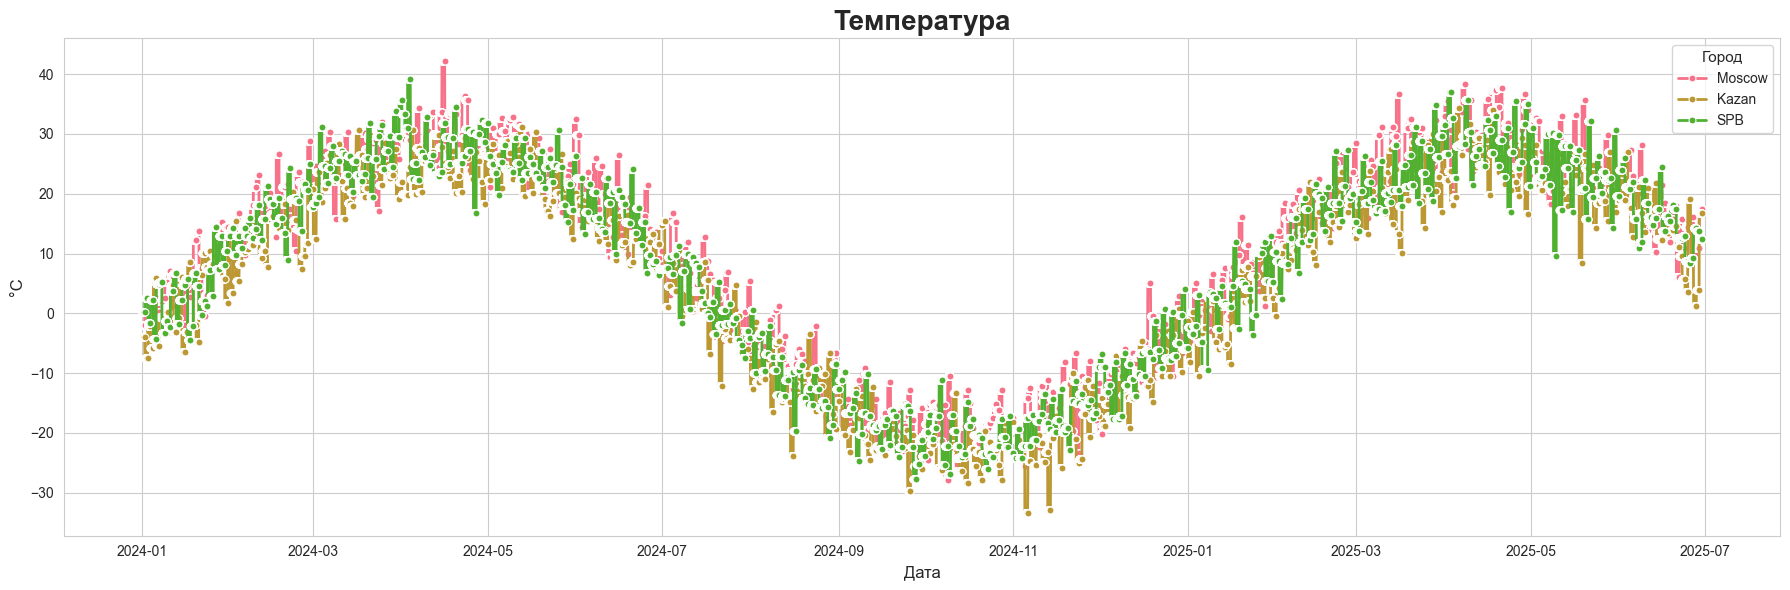

In [17]:
orders = orders.sort_values(by=['order_datetime'])

sns.set_style("whitegrid")
sns.set_palette("husl") 

plt.figure(figsize=(18, 6))

sns.lineplot(data=orders, x='order_datetime', y='temperature', hue='restaurant_city', marker='o', markersize=5, linewidth=2)

plt.title('Температура', fontsize=20, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('°C', fontsize=12)
plt.legend(title='Город', title_fontsize=11, fontsize=10)
plt.tight_layout()
plt.show()

**Температура как будто сдвинута на самом деле относительно дат: пик температур приходится на апрель-май, в летние месяцы происходит спад, минимум температур достигается в октябре, что не соответствует природе.**

In [102]:
import requests

temperature_data = pd.DataFrame(columns=['city', 'time', 'temperature'])

# составляем словари с координатами ородов
cities_coordinates = {'SPB' : (59.9386, 30.3141), 'Moscow' : (55.75396, 37.620393), 'Kazan' : (55.79, 49.13)}

for city, coordinates in cities_coordinates.items():

    params = {
        'latitude': coordinates[0],
        'longitude': coordinates[1],
        'start_date': '2024-01-01',
        'end_date': '2025-06-29',
        'hourly': 'temperature_2m',
        'timezone': 'Europe/Moscow'
    }

    url = 'https://archive-api.open-meteo.com/v1/era5?'
    response = requests.get(url, params=params)

    data = response.json()

    data_city = pd.DataFrame({'city' : city, 
                              'time' : data['hourly']['time'], 
                              'temperature' : data['hourly']['temperature_2m']})
    data_city['time'] = pd.to_datetime(data_city['time'])

    temperature_data = pd.concat([temperature_data, data_city])
    print(f'Погода для города {city} получена')

/var/folders/sf/vxx_z6h952j82hw08tmwnyvc0000gn/T/ipykernel_57323/3960011108.py:29: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  temperature_data = pd.concat([temperature_data, data_city])


Погода для города SPB получена
Погода для города Moscow получена
Погода для города Kazan получена


**Снова построим график**

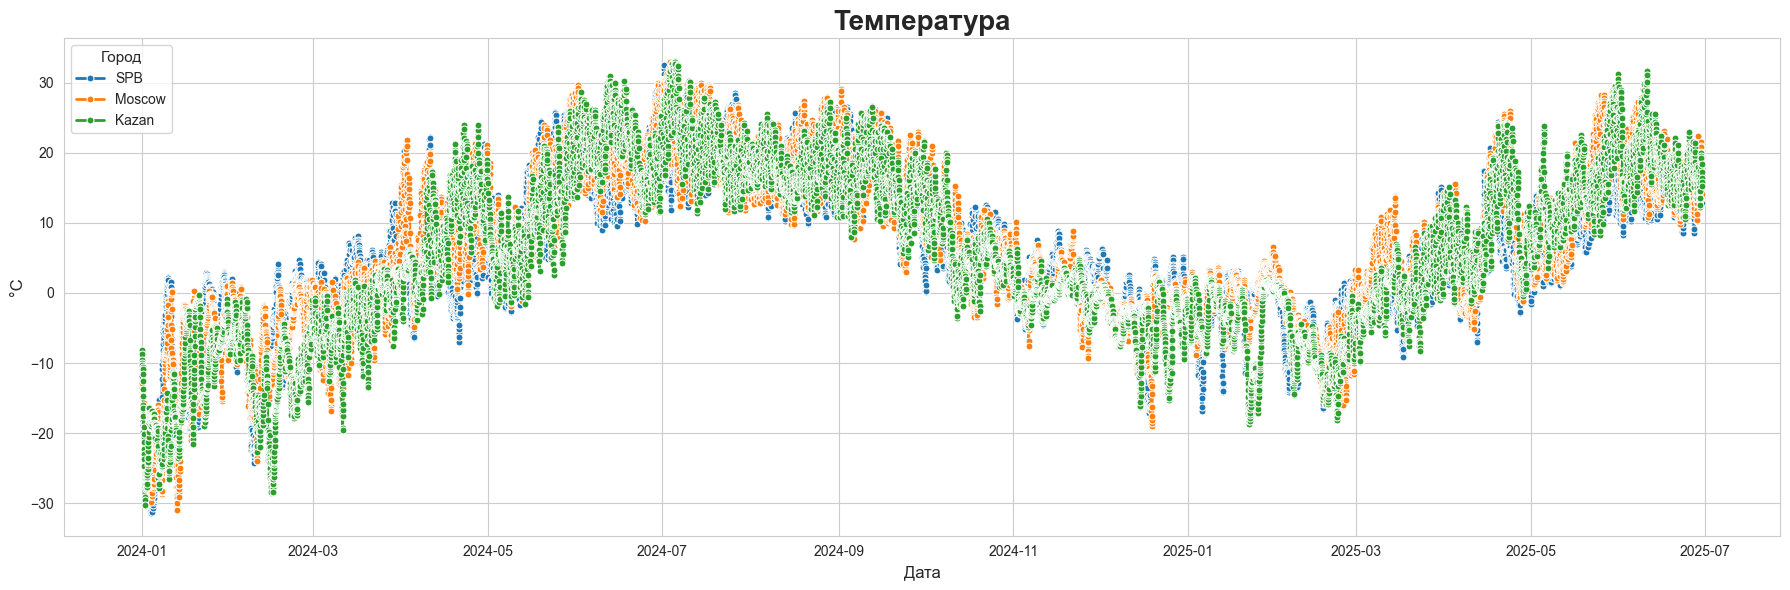

In [103]:
plt.figure(figsize=(18, 6))

sns.set_style("whitegrid")

sns.lineplot(data=temperature_data, x='time', y='temperature', hue='city', marker='o', markersize=5, linewidth=2)

plt.title('Температура', fontsize=20, fontweight='bold')
plt.xlabel('Дата', fontsize=12)
plt.ylabel('°C', fontsize=12)
plt.legend(title='Город', title_fontsize=11, fontsize=10)
plt.tight_layout()
plt.show()

**Теперь данные по температуре выглядят логично. Добавим их в orders**

In [104]:
temperature_data['hour'] = temperature_data['time'].dt.hour
temperature_data['date'] = temperature_data['time'].dt.date

# Удаляем колонку с температурой из orders
orders = orders.drop(['temperature'], axis=1)

In [105]:
orders['order_date'] = pd.to_datetime(orders['order_date'])
temperature_data['date'] = pd.to_datetime(temperature_data['date'])

In [106]:
orders = orders.merge(temperature_data.drop(['time'], axis=1), 
                      how='left',
                      left_on=['hour', 'restaurant_city', 'order_date'], 
                      right_on=['hour', 'city', 'date']).drop(['city', 'date'], axis=1)

## 5.2. Прочие данные

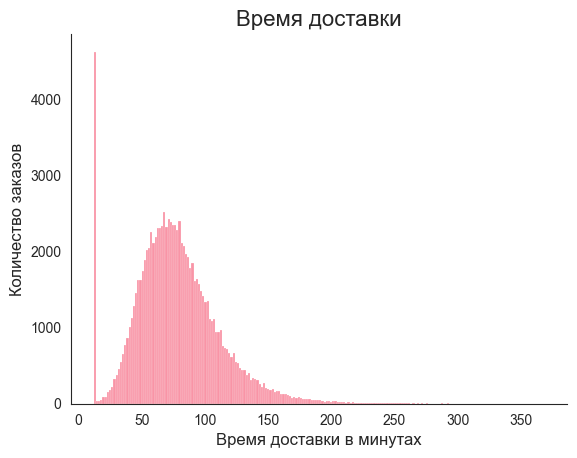

In [22]:
# Распределение целевой переменной
sns.set_style("white")
sns.histplot(data=orders, x='delivery_time_minutes')
plt.title('Время доставки', fontsize=16)
plt.xlabel('Время доставки в минутах', fontsize=12)
plt.ylabel('Количество заказов', fontsize=12)
sns.despine();

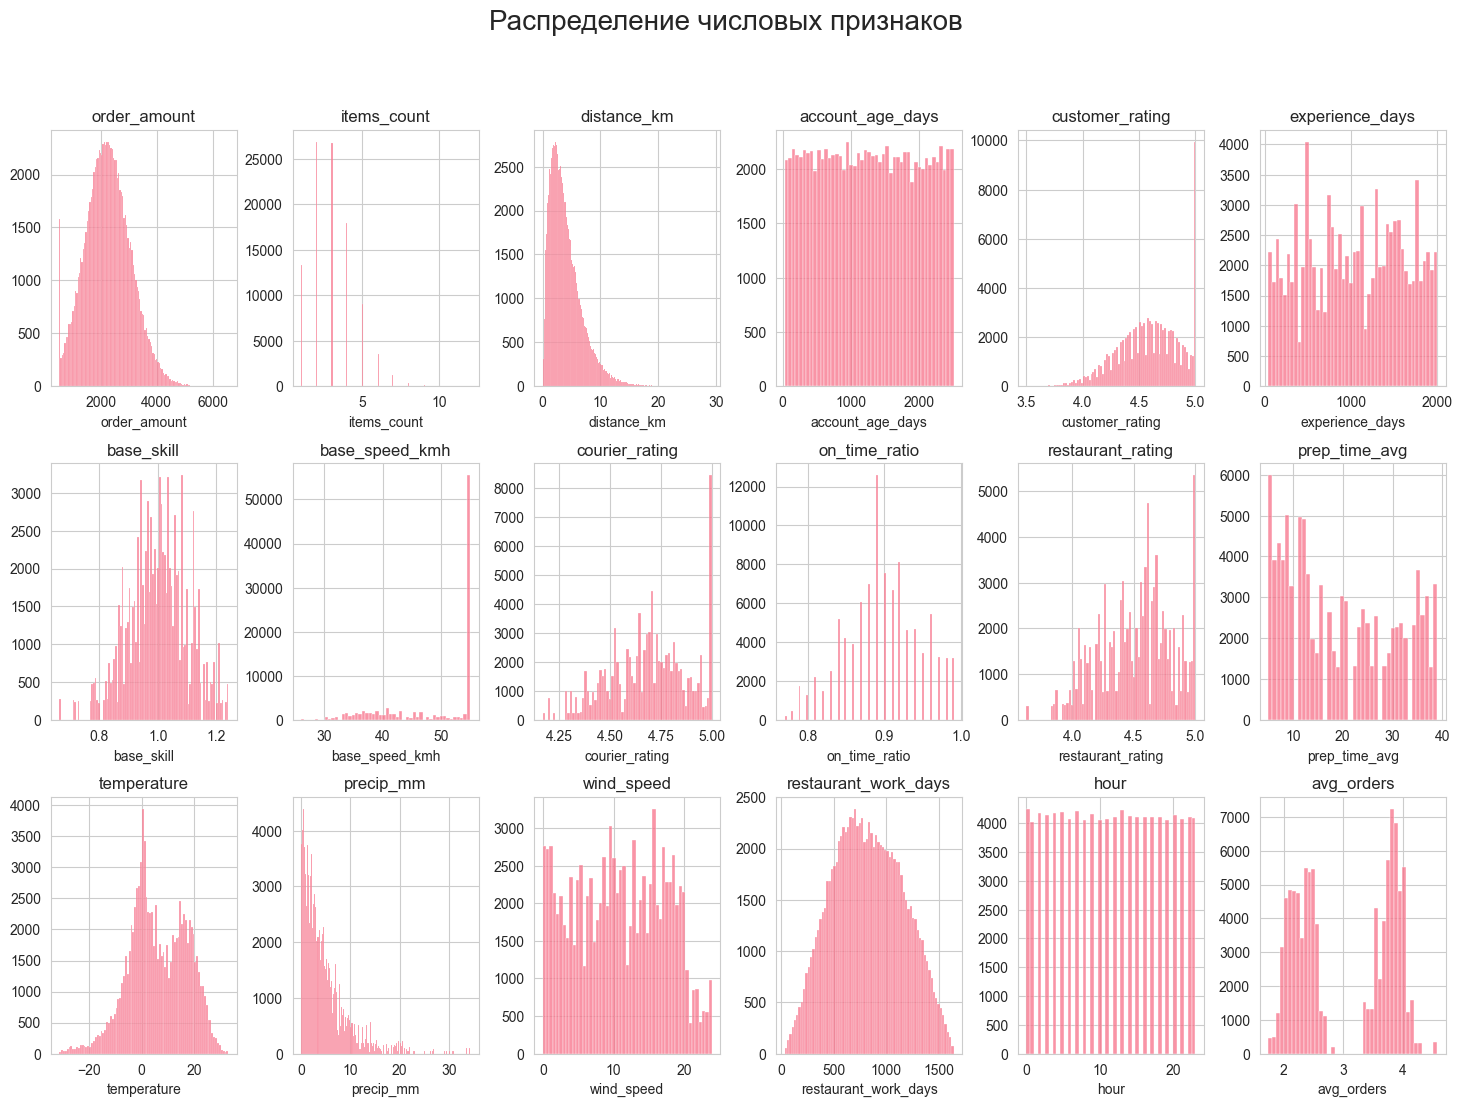

In [26]:
# Распределение всех признаков
fig, ax = plt.subplots(3, 6, figsize=(18, 12))

for i in range(len(num_features)):
    sns.histplot(data=orders, x=num_features[i], ax=ax[i//6, i%6])
    ax[i//6, i%6].set_title(num_features[i])
    ax[i//6, i%6].set_ylabel('')

plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.suptitle('Распределение числовых признаков', fontsize=20);

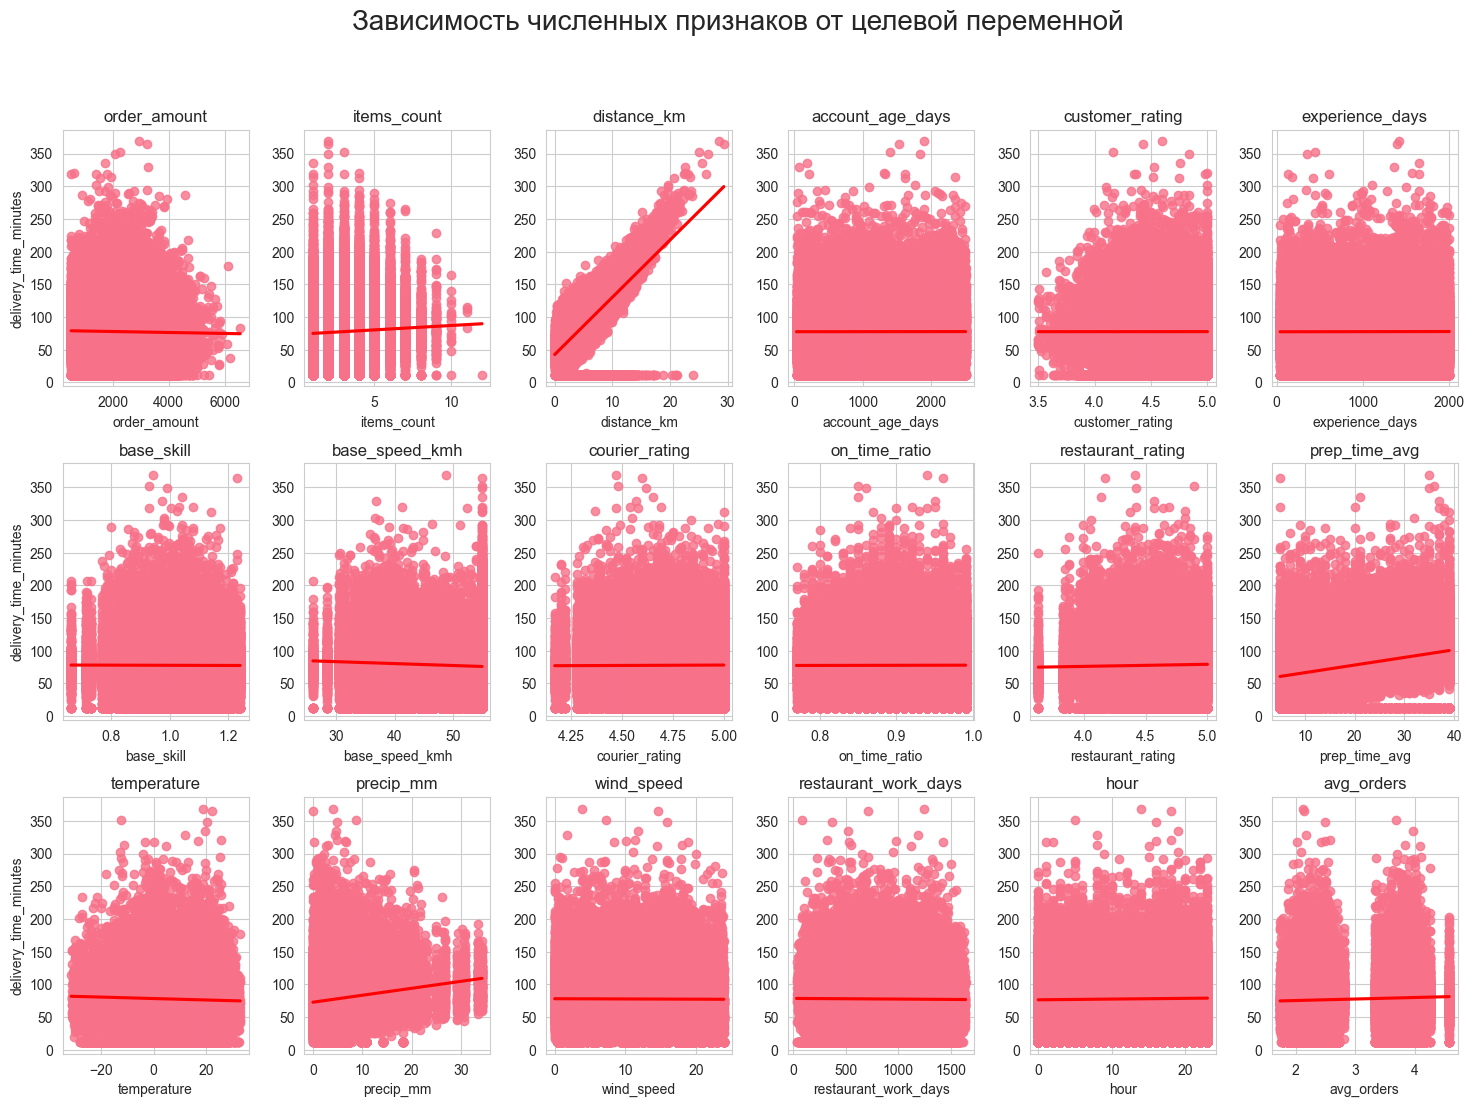

In [173]:
# Распределение числовых признаков
fig, ax = plt.subplots(3, 6, figsize=(18, 12))

for i in range(len(num_features)):
    sns.regplot(data=orders, x=num_features[i], y='delivery_time_minutes', ax=ax[i//6, i%6], ci=95, line_kws=dict(color="r"))
    ax[i//6, i%6].set_title(num_features[i])
    if i % 6 != 0:
        ax[i//6, i%6].set_ylabel('')
        ax[1//6, i%6].set_xlabel('')
    
plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.suptitle('Зависимость численных признаков от целевой переменной', fontsize=20);

**Имеется 4 признака с явно линейной связью с целевой перемнной - это distance_km, prep_time_avg, precip_mm, items_count, temperature**

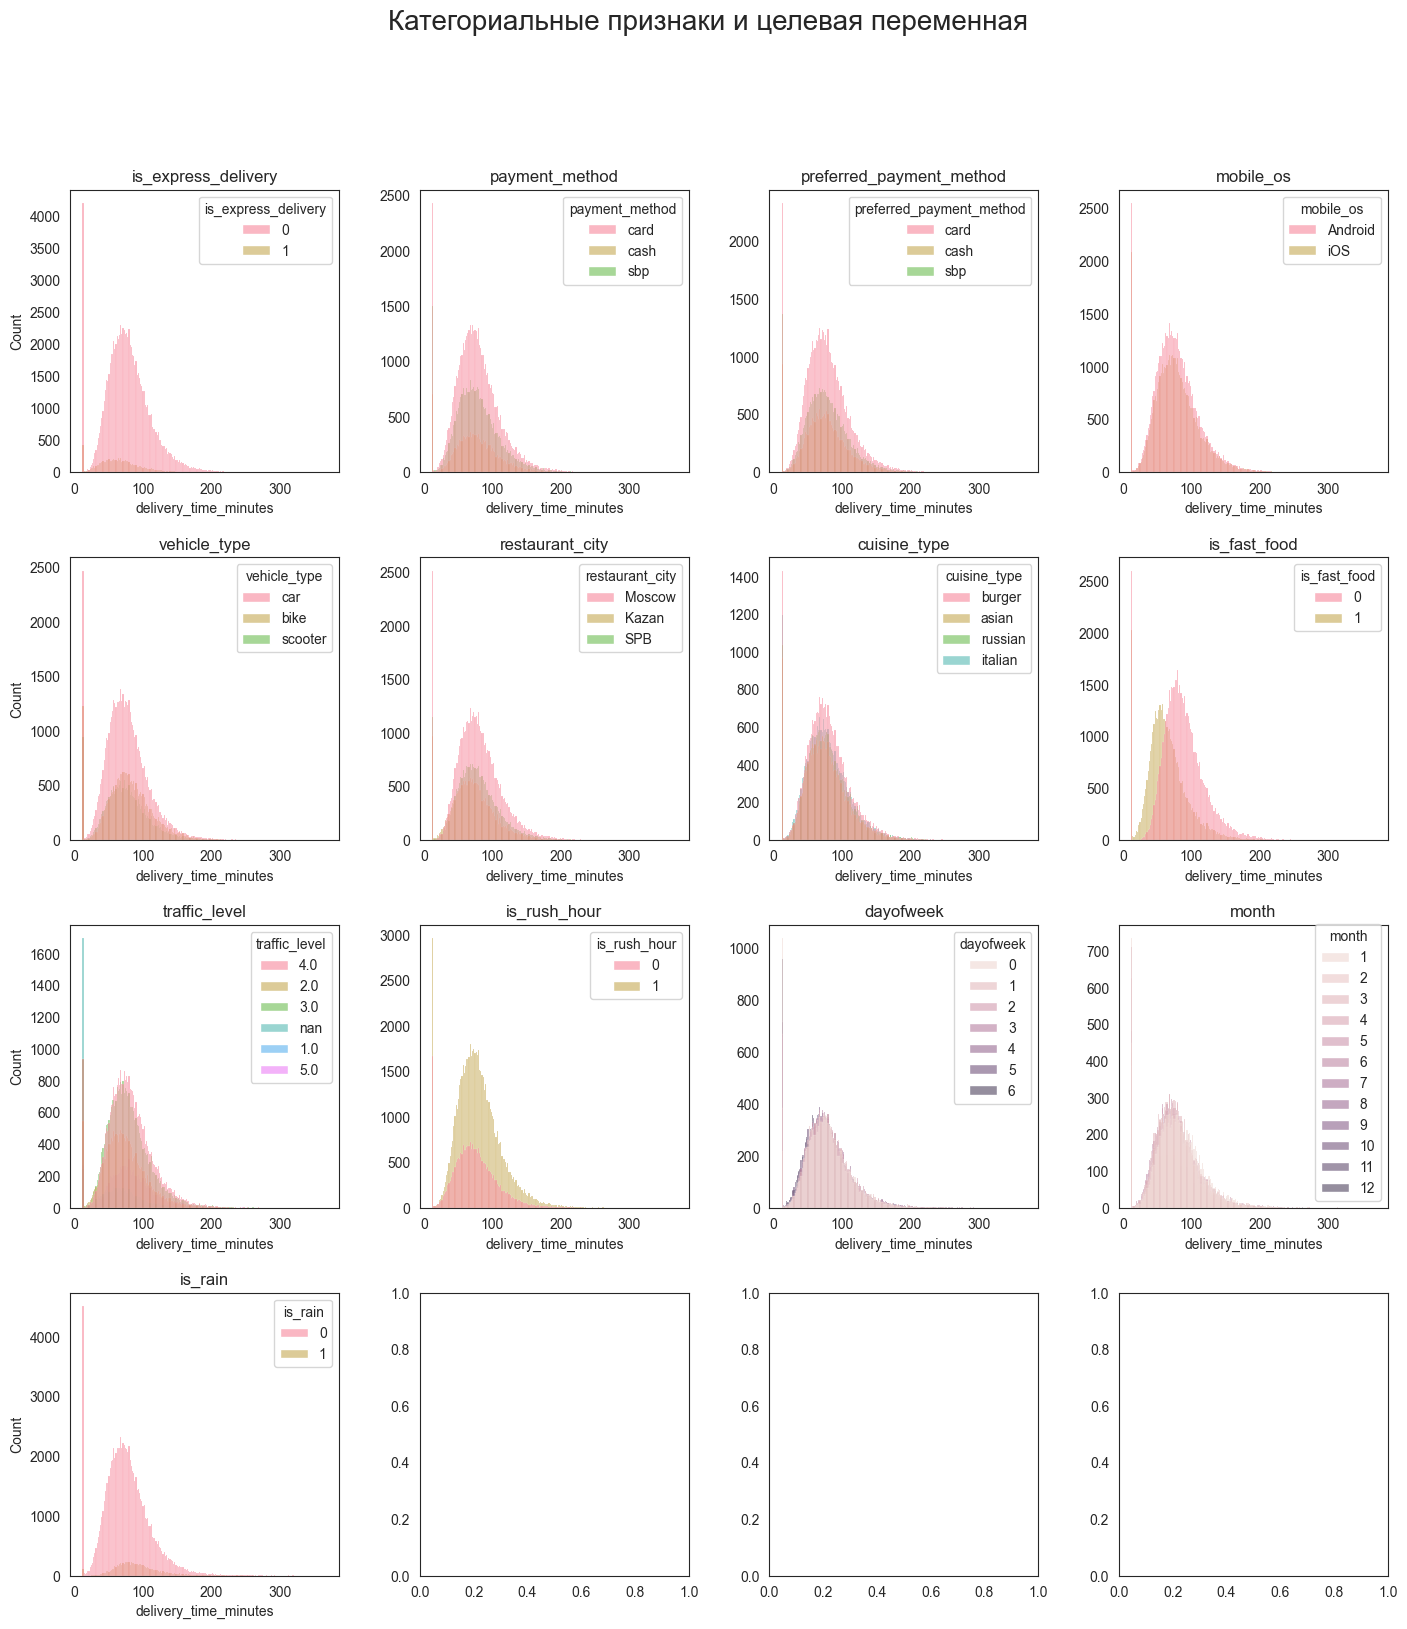

In [63]:
# Распределение категориальных признаков
fig, ax = plt.subplots(4, 4, figsize=(17, 18))

for i in range(len(cat_features)):
    sns.histplot(data=orders, x="delivery_time_minutes", hue=cat_features[i], ax=ax[i//4, i%4])
    ax[i//4, i%4].set_title(cat_features[i])
    if i % 4 != 0:
        ax[i//4, i%4].set_ylabel('')
    
plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.suptitle('Категориальные признаки и целевая переменная', fontsize=20);

**Заметно смещение распределение только у признака is_fast_food**

In [64]:
#!pip3 install phik

interval columns not set, guessing: ['order_amount', 'items_count', 'distance_km', 'is_express_delivery', 'delivery_time_minutes', 'account_age_days', 'customer_rating', 'experience_days', 'base_skill', 'base_speed_kmh', 'courier_rating', 'on_time_ratio', 'is_fast_food', 'restaurant_rating', 'prep_time_avg', 'precip_mm', 'wind_speed', 'is_rush_hour', 'restaurant_work_days', 'hour', 'dayofweek', 'avg_orders', 'month', 'is_rain', 'temperature']


<Figure size 1600x900 with 0 Axes>

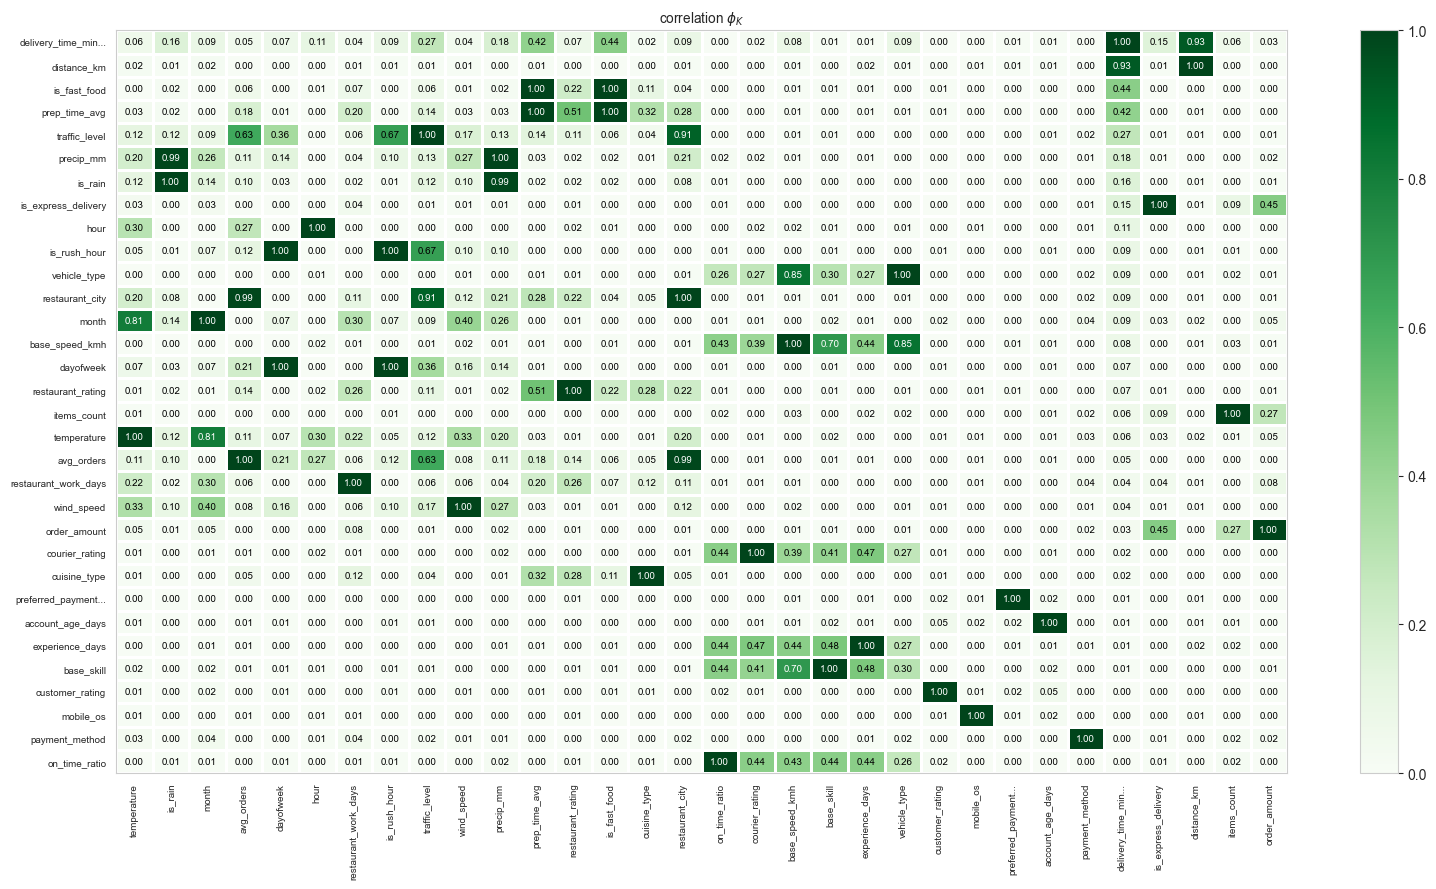

In [174]:
import phik
from phik.report import plot_correlation_matrix

phik_overview = (
    orders.drop(['order_id', 'order_date', 'order_datetime', 'open_date'], axis=1)
      .phik_matrix()
      .round(2)
      .sort_values('delivery_time_minutes')
)

plt.figure(figsize=(16, 9))
plot_correlation_matrix(
    phik_overview.values,
    x_labels=phik_overview.columns,
    y_labels=phik_overview.index,
    vmin=0,
    vmax=1,
    color_map="Greens",
    title=r"correlation $\phi_K$",
    fontsize_factor=0.7,
    figsize=(16, 9),
)
plt.tight_layout()
plt.show();

Сильные зависимости (> 0.6) наблюдаются у следующих пар признаков:   
- `delivery_time_minutes -- distance_km -> 0.93`
- `base_speed kmh -- base_skill -> 0.7`
- `base_speed kmh -- vehicle_type -> 0.85`
- `month -- temperature -> 0.88`
- `avg_orders -- traffic_level -> 0.62`
- `prep_time_avg -- restaurant_rating -> 0.51`
- `restaurant_city -- traffic_level -> 0.67`
- `avg_orders -- restaurant_city -> 0.99` 

## 6. Train - test split

In [107]:
orders = orders.sort_values(['order_datetime'])

q60 = orders['order_datetime'].quantile(0.60)
q80 = orders['order_datetime'].quantile(0.80)

# Разделяем на подвыборки
train_df = orders[orders['order_datetime'] < q60].copy()
val_df = orders[(orders['order_datetime'] >= q60)&(orders['order_datetime'] < q80)].copy()
oot_df = orders[orders['order_datetime'] >= q80].copy()

train_df = train_df.drop(['order_id', 'order_date', 'order_datetime', 'open_date'], axis=1)
val_df = val_df.drop(['order_id', 'order_date', 'order_datetime', 'open_date'], axis=1)
oot_df = oot_df.drop(['order_id', 'order_date', 'order_datetime', 'open_date'], axis=1)

print('Train shape:', train_df.shape)
print('Val shape:', val_df.shape)
print('OOT shape:  ', oot_df.shape)

Train shape: (59408, 32)
Val shape: (19802, 32)
OOT shape:   (19803, 32)


## 6. Удаление выбросов

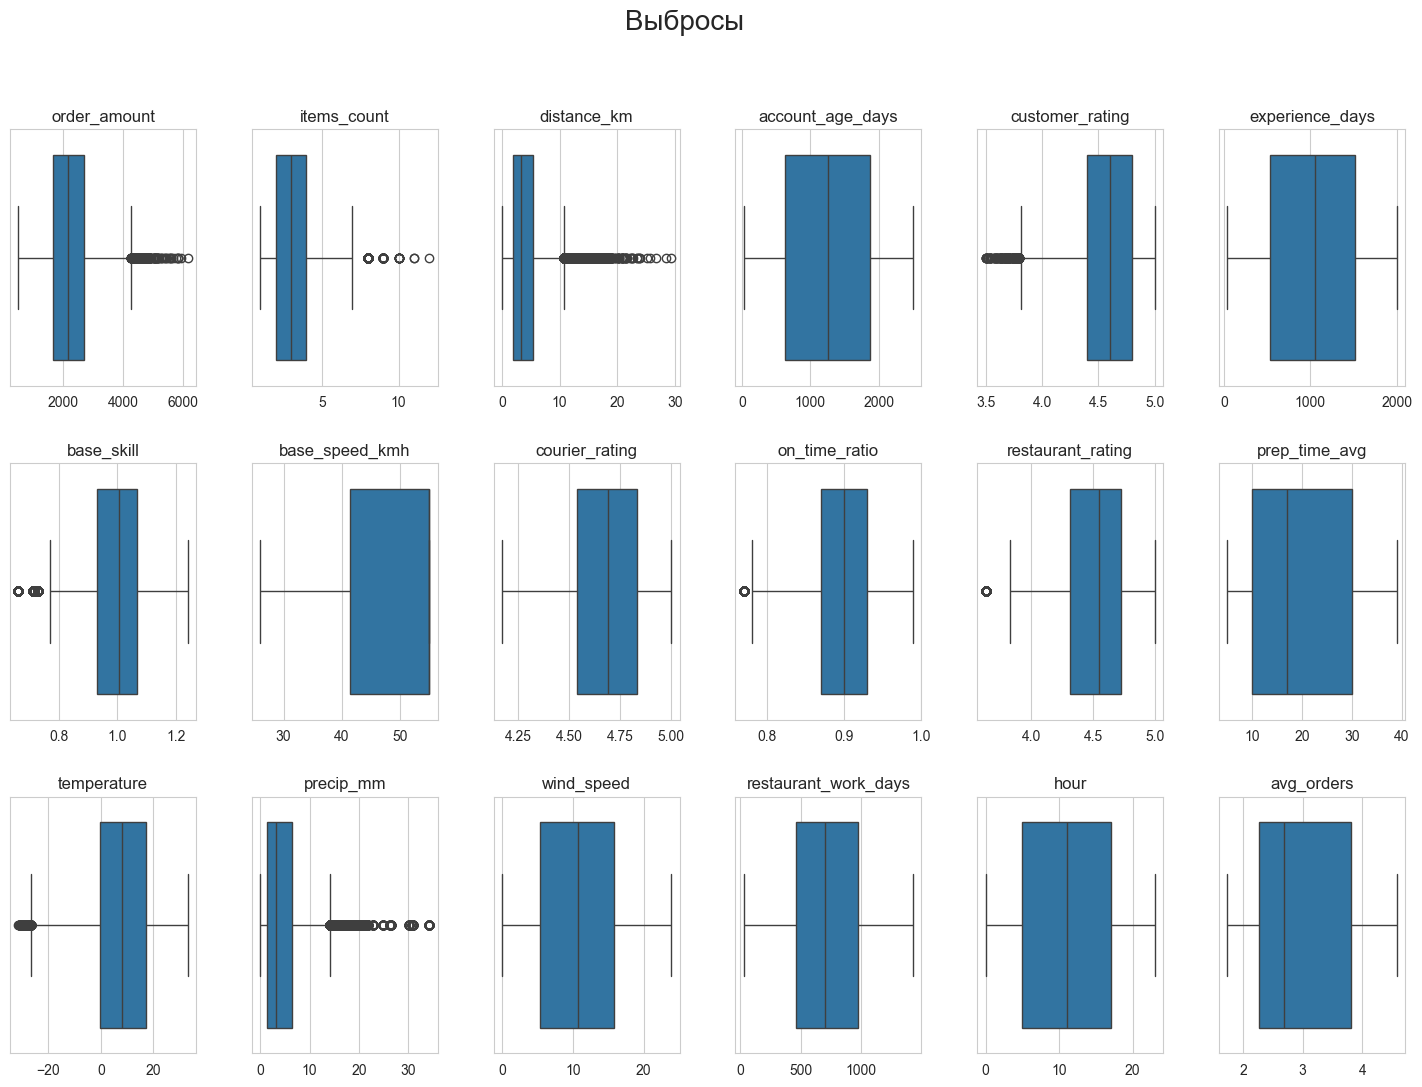

In [108]:
fig, ax = plt.subplots(3, 6, figsize=(18, 12))

for i in range(len(num_features)):
    sns.boxplot(x=train_df[num_features[i]], ax=ax[i//6, i%6])
    ax[i//6, i%6].set_title(num_features[i])
    ax[i//6, i%6].set_xlabel('')
    
plt.subplots_adjust(hspace=0.3, wspace=0.3)
plt.suptitle('Выбросы', fontsize=20);

**Выбросы присутствуют всего в нескольких столбцах. Удалим выбросы из этих нескольких столбцов с помощью межквартильного размаха**

In [109]:
 def IQR(df: pd.DataFrame, 
        column_name : str) -> Tuple[pd.DataFrame, pd.DataFrame]:
    """Функция для удаления выбросов в колонке датафрейма"""
    
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_filtered = df[(df[column_name] >= lower_bound) & (df[column_name] <= upper_bound)]
    df_deleted_upper = df[df[column_name] >= upper_bound]
    
    return df_filtered, df_deleted_upper

In [110]:
print(train_df.shape)

(59408, 32)


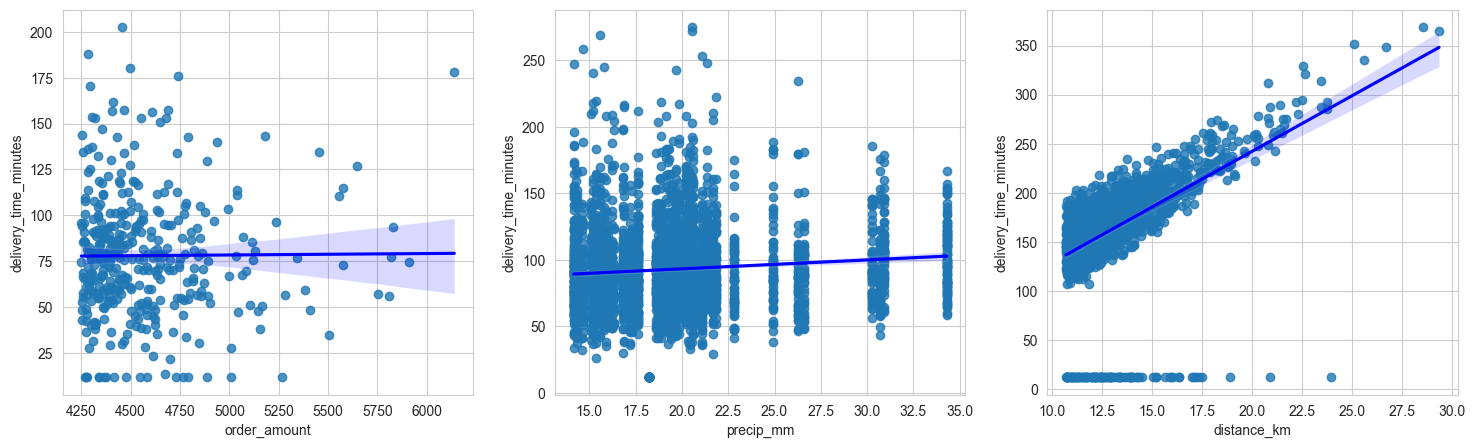

In [111]:
# Посмотрим на зависимость больших значений признака и целевой переменной (смотрим на те признаки, где много было обнаружено много выбросов)
features_outliers = ['order_amount', 'precip_mm', 'distance_km']
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

for i in range(len(features_outliers)):
    _, df_deleted_upper = IQR(train_df, features_outliers[i])
    sns.regplot(data=df_deleted_upper, x=features_outliers[i], y='delivery_time_minutes', ax=ax[i%3], ci=95, line_kws=dict(color="b"));

In [112]:
for column_name in ['order_amount', 'items_count', 'customer_rating', 'base_skill', 'on_time_ratio', 'restaurant_rating']:
    train_df, _ = IQR(train_df, column_name)

In [113]:
train_df = train_df[~((train_df['delivery_time_minutes'] < 50)&(train_df['distance_km'] > 10))]
    
train_df.shape

(57543, 32)

## 7. AutoML

### 7.1. LightAutoML

In [107]:
from lightautoml.automl.presets.tabular_presets import TabularAutoML, TabularUtilizedAutoML
from lightautoml.tasks import Task
from lightautoml.report.report_deco import ReportDeco, ReportDecoUtilized
from lightautoml.addons.tabular_interpretation import SSWARM
from sklearn.metrics import r2_score, mean_absolute_error

N_THREADS = 1 # Параллельные вычисления не работают на чипе macbook, нужно что-то менять в настройках python
N_FOLDS = 5
RANDOM_STATE = 42
TEST_SIZE = 0.2
TIMEOUT = 300
target_col = 'delivery_time_minutes'

np.random.seed(RANDOM_STATE)
torch.set_num_threads(N_THREADS)

**Будем использовать функцию средней абсолютной ошибки в качестве лосс-функции, т.к. она интерпретируема: измеряется в тех же единицах, что и целевая переменная. Минус использования MAE только в меньшей чувствительности к выбросами, чем RMSE Выбросов судя по графикам не много.**

In [ ]:
task = Task('reg')

roles = {'target': target_col}

automl = TabularAutoML(
    task = task,
    timeout = TIMEOUT,
    cpu_limit = N_THREADS,
    reader_params = {'n_jobs': N_THREADS, 'cv': N_FOLDS, 'random_state': RANDOM_STATE},
)

out_of_fold_predictions = automl.fit_predict(train_df, roles = roles, verbose = 1)

[20:01:25] Stdout logging level is INFO.
[20:01:25] Copying TaskTimer may affect the parent PipelineTimer, so copy will create new unlimited TaskTimer
[20:01:25] Task: reg

[20:01:25] Start automl preset with listed constraints:
[20:01:25] - time: 300.00 seconds
[20:01:25] - CPU: 1 cores
[20:01:25] - memory: 16 GB

[20:01:25] Train data shape: (54335, 31)

[20:01:26] Layer 1 train process start. Time left 298.96 secs
[20:01:27] Start fitting Lvl_0_Pipe_0_Mod_0_LinearL2 ...
[20:01:29] Fitting Lvl_0_Pipe_0_Mod_0_LinearL2 finished. score = -135.05393389987447
[20:01:29] Lvl_0_Pipe_0_Mod_0_LinearL2 fitting and predicting completed
[20:01:29] Time left 296.80 secs

[20:01:31] Selector_LightGBM fitting and predicting completed
[20:01:32] Start fitting Lvl_0_Pipe_1_Mod_0_LightGBM ...
[20:01:46] Fitting Lvl_0_Pipe_1_Mod_0_LightGBM finished. score = -61.01154145878777
[20:01:46] Lvl_0_Pipe_1_Mod_0_LightGBM fitting and predicting completed
[20:01:46] Start hyperparameters optimization for Lvl_0_

Optimization Progress:   0%|                                                                    | 0/101 [00:00<?, ?it/s][I 2026-05-30 20:01:46,742] A new study created in memory with name: no-name-8ac5b208-4223-4a50-967d-8da6e6597f1b
[I 2026-05-30 20:01:51,930] Trial 0 finished with value: -66.00510896071032 and parameters: {'feature_fraction': 0.6872700594236812, 'num_leaves': 244, 'bagging_fraction': 0.8659969709057025, 'min_sum_hessian_in_leaf': 0.24810409748678125, 'reg_alpha': 2.5361081166471375e-07, 'reg_lambda': 2.5348407664333426e-07}. Best is trial 0 with value: -66.00510896071032.
Optimization Progress:   4%|█▏                            | 4/101 [00:16<06:48,  4.22s/it, best_trial=2, best_value=-64]

[20:02:03] Hyperparameters optimization for Lvl_0_Pipe_1_Mod_1_Tuned_LightGBM completed
[20:02:03] Start fitting Lvl_0_Pipe_1_Mod_1_Tuned_LightGBM ...


[20:02:12] Fitting Lvl_0_Pipe_1_Mod_1_Tuned_LightGBM finished. score = -61.702980631056576
[20:02:12] Lvl_0_Pipe_1_Mod_1_Tuned_LightGBM fitting and predicting completed
[20:02:12] Start fitting Lvl_0_Pipe_1_Mod_2_CatBoost ...
[20:02:32] Fitting Lvl_0_Pipe_1_Mod_2_CatBoost finished. score = -86.80718392689455
[20:02:32] Lvl_0_Pipe_1_Mod_2_CatBoost fitting and predicting completed
[20:02:32] Start hyperparameters optimization for Lvl_0_Pipe_1_Mod_3_Tuned_CatBoost ... Time budget is 97.57 secs


Optimization Progress:   0%|                                                                    | 0/101 [00:00<?, ?it/s][I 2026-05-30 20:02:32,012] A new study created in memory with name: no-name-5e740abb-e330-488b-91e4-6f5b71a3efa0
[I 2026-05-30 20:02:37,486] Trial 0 finished with value: -96.96829219958528 and parameters: {'max_depth': 4, 'nan_mode': 'Max', 'l2_leaf_reg': 0.0024430162614261413, 'min_data_in_leaf': 4}. Best is trial 0 with value: -96.96829219958528.
Optimization Progress:  22%|█████▋                    | 22/101 [01:43<06:10,  4.69s/it, best_trial=21, best_value=-95.3]

[20:04:15] Hyperparameters optimization for Lvl_0_Pipe_1_Mod_3_Tuned_CatBoost completed
[20:04:15] Start fitting Lvl_0_Pipe_1_Mod_3_Tuned_CatBoost ...


In [161]:
print(automl.create_model_str_desc())

Final prediction for new objects (level 0) = 
	 0.76336 * (5 averaged models Lvl_0_Pipe_1_Mod_0_LightGBM) +
	 0.14751 * (5 averaged models Lvl_0_Pipe_1_Mod_1_Tuned_LightGBM) +
	 0.08913 * (5 averaged models Lvl_0_Pipe_1_Mod_2_CatBoost) 


In [162]:
train_preds_laml = automl.predict(train_df)
oot_preds_laml = automl.predict(oot_df)

print(f'R2 train score: {round(r2_score(train_df['delivery_time_minutes'].values, train_preds_laml.data[:,0]), 4)}')
print(f'R2 oot score: {round(r2_score(oot_df['delivery_time_minutes'].values, oot_preds_laml.data[:,0]), 4)}')

print(f'MAE train score: {round(mean_absolute_error(train_df['delivery_time_minutes'].values, train_preds_laml.data[:,0]), 4)}')
print(f'MAE oot score: {round(mean_absolute_error(oot_df['delivery_time_minutes'].values, oot_preds_laml.data[:,0]), 4)}')

R2 train score: 0.9603
R2 oot score: 0.7762
MAE train score: 5.3047
MAE oot score: 7.6621


**Модель получилась сильно переобученной. Оптимальная модель содержит градиентный бустинг.**

**Посмотрим, какие признаки automl отобрал для формирования прогнозов:**

In [163]:
selected_feats = automl.collect_used_feats()
print('Количество признаков, использовывавшиеся при формировании прогнозов:', len(selected_feats), '\n',
      'Всего количество признаков в датасете: ', train_df.shape[1])

Количество признаков, использовывавшиеся при формировании прогнозов: 24 
 Всего количество признаков в датасете:  31


**Какие признаки для lightautoml оказались не важны:**

In [164]:
print('Неважные по мнению модели признаки: ', 
      [feat for feat in list(train_df.columns) if feat not in selected_feats and feat != 'delivery_time_minutes'])

Неважные по мнению модели признаки:  ['payment_method', 'preferred_payment_method', 'mobile_os', 'vehicle_type', 'restaurant_city', 'cuisine_type']


### 7.2 AutoGluon

In [165]:
from autogluon.tabular import TabularDataset, TabularPredictor
from autogluon.features.generators import AutoMLPipelineFeatureGenerator 

time_limit = 300  
metric = 'mean_absolute_error'  

# попробуем воспользоваться методом генерации признаков, посмотрим, что это даст
auto_ml_pipeline_feature_generator = AutoMLPipelineFeatureGenerator()
auto_ml_pipeline_feature_generator.fit_transform(X=train_df.drop(['delivery_time_minutes'], axis=1))

Fitting AutoMLPipelineFeatureGenerator...
	Available Memory:                    4566.01 MB
	Train Data (Original)  Memory Usage: 30.91 MB (0.7% of available memory)
	Inferring data type of each feature based on column values. Set feature_metadata_in to manually specify special dtypes of the features.
	Stage 1 Generators:
		Fitting AsTypeFeatureGenerator...
			Note: Converting 4 features to boolean dtype as they only contain 2 unique values.
	Stage 2 Generators:
		Fitting FillNaFeatureGenerator...
	Stage 3 Generators:
		Fitting IdentityFeatureGenerator...
		Fitting CategoryFeatureGenerator...
			Fitting CategoryMemoryMinimizeFeatureGenerator...
	Stage 4 Generators:
		Fitting DropUniqueFeatureGenerator...
	Stage 5 Generators:
		Fitting DropDuplicatesFeatureGenerator...
	Types of features in original data (raw dtype, special dtypes):
		('float', [])  : 13 | ['order_amount', 'distance_km', 'customer_rating', 'base_skill', 'base_speed_kmh', ...]
		('int', [])    : 11 | ['items_count', 'is_e

,order_amount,items_count,distance_km,is_express_delivery,account_age_days,mobile_os,customer_rating,experience_days,base_skill,base_speed_kmh,...,restaurant_work_days,hour,dayofweek,avg_orders,month,payment_method,preferred_payment_method,vehicle_type,restaurant_city,cuisine_type
88492,2306.38,3,1.45,0,1752,0,5.00,1735,0.902997,55.000000,...,847,0,0,3.727273,1,0,0,1,1,1
1578,2251.00,7,6.06,0,1976,0,4.88,832,0.961247,35.369150,...,41,0,0,3.727273,1,1,1,0,1,1
90172,500.00,1,11.52,0,2313,1,4.43,426,0.865174,55.000000,...,57,0,0,3.727273,1,0,0,1,1,0
64161,1973.85,3,0.84,0,1023,0,4.44,1451,1.062545,55.000000,...,172,0,0,3.727273,1,1,0,2,1,1
65016,1056.22,2,1.89,0,1610,1,4.30,1570,0.942086,55.000000,...,827,0,0,1.966667,1,2,2,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
97482,2915.96,6,2.49,0,699,1,3.84,1987,0.984659,55.000000,...,886,9,0,2.128571,11,0,2,1,0,1
3831,4024.74,2,1.83,1,928,0,4.84,1911,1.170164,45.195252,...,1205,9,0,3.776316,11,2,0,0,1,3
85439,1850.25,3,3.07,0,259,1,4.36,546,0.974594,55.000000,...,623,9,0,3.776316,11,0,1,1,1,0
16196,2098.17,3,2.69,0,2167,1,4.73,1737,0.872984,55.000000,...,865,9,0,3.776316,11,1,0,1,1,2


**AutoGluon просто закодировал категориальные признаки**

In [166]:
predictor = TabularPredictor(
    'delivery_time_minutes',
    eval_metric=metric).fit(train_df,
                            time_limit=time_limit,
                            presets='good_quality'
                            )

No path specified. Models will be saved in: "AutogluonModels/ag-20260517_121948"
Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.13
Operating System:   Darwin
Platform Machine:   arm64
Platform Version:   Darwin Kernel Version 25.3.0: Wed Jan 28 20:54:55 PST 2026; root:xnu-12377.91.3~2/RELEASE_ARM64_T8132
CPU Count:          10
Pytorch Version:    2.9.1
CUDA Version:       CUDA is not available
GPU Count:          WARNING: Exception was raised when calculating GPU count (AssertionError)
Memory Avail:       4.46 GB / 16.00 GB (27.9%)
Disk Space Avail:   126.43 GB / 228.27 GB (55.4%)
Presets specified: ['good_quality']
Using hyperparameters preset: hyperparameters='light'
Setting dynamic_stacking from 'auto' to True. Reason: Enable dynamic_stacking when use_bag_holdout is disabled. (use_bag_holdout=False)
Stack configuration (auto_stack=True): num_stack_levels=1, num_bag_folds=8, num_bag_sets=1
Note: `

In [167]:
predictor.leaderboard()

,model,score_val,eval_metric,pred_time_val,fit_time,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L3,-5.881170,mean_absolute_error,28.252860,136.060434,0.001096,0.193078,3,False,13
1,RandomForestMSE_BAG_L2,-5.893891,mean_absolute_error,27.950606,133.785040,0.619534,21.500527,2,False,10
2,LightGBM_BAG_L2,-5.929161,mean_absolute_error,27.632230,114.366829,0.301158,2.082316,2,False,9
3,CatBoost_BAG_L2,-6.080500,mean_absolute_error,27.420252,132.207273,0.089180,19.922760,2,False,11
4,LightGBMXT_BAG_L2,-6.182384,mean_absolute_error,29.739633,118.556453,2.408561,6.271940,2,False,8
5,NeuralNetFastAI_BAG_L2,-6.537236,mean_absolute_error,27.692981,116.087125,0.361909,3.802612,2,False,12
6,WeightedEnsemble_L2,-6.634398,mean_absolute_error,25.478307,30.081329,0.001072,0.106484,2,False,7
7,LightGBM_BAG_L1,-6.648086,mean_absolute_error,2.316157,5.532349,2.316157,5.532349,1,False,2
8,LightGBMXT_BAG_L1,-7.160957,mean_absolute_error,23.161078,24.442496,23.161078,24.442496,1,False,1
9,CatBoost_BAG_L1,-7.886309,mean_absolute_error,0.107071,51.731280,0.107071,51.731280,1,False,4


**Модель WeightedEnsemble_L3 — это финальная модель верхнего уровня, которая объединяет предсказания всех лучших моделей из предыдущих уровней (L2), присваивая каждой из них определенный "вес" для получения наиболее точного итогового прогноза**

In [168]:
predictor.feature_importance(oot_df)

Computing feature importance via permutation shuffling for 30 features using 5000 rows with 5 shuffle sets...
	220.9s	= Expected runtime (44.18s per shuffle set)
	162.89s	= Actual runtime (Completed 5 of 5 shuffle sets)


,importance,stddev,p_value,n,p99_high,p99_low
distance_km,18.504240,0.315995,1.020109e-08,5,19.154877,17.853602
prep_time_avg,7.477717,0.182513,4.255317e-08,5,7.853513,7.101921
precip_mm,1.541343,0.076334,7.195217e-07,5,1.698516,1.384169
hour,1.362847,0.069270,7.981365e-07,5,1.505474,1.220219
traffic_level,1.110645,0.078120,2.917944e-06,5,1.271496,0.949795
is_express_delivery,1.022921,0.043549,3.932551e-07,5,1.112589,0.933253
items_count,0.493739,0.031004,1.855919e-06,5,0.557576,0.429902
is_fast_food,0.476242,0.066552,4.459584e-05,5,0.613274,0.339210
month,0.448556,0.097902,2.558533e-04,5,0.650138,0.246974
vehicle_type,0.253346,0.035167,4.343194e-05,5,0.325756,0.180936


**Согласно AutoGluon часть признаков даже ухудшают качество модели. Возможно, в них много выбросов**    
**Столбец n в таблице feature_importance означает количество перестановок, использованных для оценки важности каждого признака (Значение признака случайным образом перемешивается n=5 раз)**

In [192]:
model_info = predictor._trainer.get_model_info('WeightedEnsemble_L3')
print('Итоговая модель - это Ансамбль моделей второго уровня со следующими весами:', 
      model_info['children_info']['S1F1']['model_weights'])

Итоговая модель - это Ансамбль моделей второго уровня со следующими весами: {'LightGBM_BAG_L2': 0.32, 'RandomForestMSE_BAG_L2': 0.68}


In [193]:
predictor.evaluate(train_df), predictor.evaluate(oot_df)

({'mean_absolute_error': -5.018848939042126,
  'root_mean_squared_error': -6.548202291010036,
  'mean_squared_error': -42.878953243989095,
  'r2': 0.9637041440432377,
  'pearsonr': 0.9817036878408467,
  'median_absolute_error': -4.076414108276367},
 {'mean_absolute_error': -10.76496997906067,
  'root_mean_squared_error': -20.146739755039626,
  'mean_squared_error': -405.89112275729417,
  'r2': 0.6114838365265038,
  'pearsonr': 0.8039115195535583,
  'median_absolute_error': -5.825999450683597})

**Модель снова получилась очень переобученной**

## 8. Настройка MLflow

In [2]:
# Устанавливаем tracking URI
mlflow.set_tracking_uri("sqlite:///mlflow.db")

# Создание эксперимента
experiment_name = "final_project_simulator_ds"

try:
    experiment_id = mlflow.create_experiment(experiment_name)
    print(f"Создан новый эксперимент: {experiment_name}")
except:
    experiment_id = mlflow.get_experiment_by_name(experiment_name).experiment_id
    print(f"Используется существующий эксперимент: {experiment_name}")

mlflow.set_experiment(experiment_name)
print(f"Текущий эксперимент: {mlflow.get_experiment(experiment_id).name}")

Используется существующий эксперимент: final_project_simulator_ds
Текущий эксперимент: final_project_simulator_ds


In [70]:
# Запуск локального сервера в терминале (перейти в папку "Финальный проект" и выполнить команду:
# mlflow server --backend-store-uri sqlite:///mlflow.db --port 5000

In [71]:
with mlflow.start_run():
    mlflow.log_param("test_param", "test_value")
    print("✓ Successfully connected to MLflow!")

✓ Successfully connected to MLflow!


## 8. Baseline Model

In [72]:
from catboost import Pool

# Формируем матрицы признаков и целевые переменные
X_train = train_df.drop([target_col], axis=1)
y_train = train_df[target_col]

X_val = val_df.drop([target_col], axis=1)
y_val = val_df[target_col]

X_oot = oot_df.drop(target_col, axis=1)
y_oot = oot_df[target_col]

# Создаем Pool-объекты
train_pool = Pool(data=X_train, label=y_train, cat_features=cat_features)
val_pool   = Pool(X_val,  label=y_val, cat_features=cat_features)
oot_pool   = Pool(X_oot,  label=y_oot, cat_features=cat_features)

In [73]:
print(f"MLflow Tracking URI: {mlflow.get_tracking_uri()}")
print(f"Active Experiment: {mlflow.get_experiment_by_name('final_project_simulator_ds')}")

MLflow Tracking URI: sqlite:///mlflow.db
Active Experiment: <Experiment: artifact_location=('/Users/darya/Desktop/Data Science/Симулятор Data Science/Финальный '
 'проект/mlruns/1'), creation_time=1779093543321, experiment_id='1', last_update_time=1779093543321, lifecycle_stage='active', name='final_project_simulator_ds', tags={}, trace_location=None, workspace='default'>


In [74]:
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import json

with mlflow.start_run(run_name="baseline"):

    mlflow.set_tag("model", "Catboost_regression")
    mlflow.set_tag("experiment_stage", "baseline")
    mlflow.set_tag("features", "all_features")
    
    cb_baseline = CatBoostRegressor(
        iterations=1000,
        depth=5,
        loss_function='MAE',
        eval_metric='MAE',
        early_stopping_rounds=100,
        verbose=False # используется для управления выводом информации в консоль/лог во время обучения модели
    )

    cb_baseline.fit(train_pool)

    y_pred = cb_baseline.predict(X_val)

    mae= mean_absolute_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)

    mlflow.log_params({"iterations":1000, "max_depth":5})

    mlflow.log_metric("mae", mae)
    mlflow.log_metric("r2", r2)

    mlflow.sklearn.log_model(cb_baseline, "model")
        
    mlflow.log_artifact("features.json")
    
    print(f"MAE: {mae:.3f}")
    print(f"R2:   {r2:.3f}")

MAE: 8.445
R2:   0.828


In [75]:
pred_train = cb_baseline.predict(train_pool)
pred_val = cb_baseline.predict(val_pool)
pred_oot = cb_baseline.predict(oot_pool)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def metrics_row(name, y_true, y_pred):
    return {
        "split": name,
        "MAE":   float(mean_absolute_error(y_true, y_pred)),
        "R2":    float(r2_score(y_true, y_pred)),
    }

rows = [
    metrics_row("Train", y_train, pred_train),
    metrics_row("Val",   y_val,   pred_val),
    metrics_row("OOT",   y_oot,   pred_oot),
]

result = pd.DataFrame(rows).set_index("split")

print(result.round({"MAE":3, "R2":4}))

         MAE      R2
split               
Train  7.247  0.8730
Val    8.445  0.8283
OOT    7.130  0.8326


In [76]:
cb_baseline.get_feature_importance(prettified=True)

,Feature Id,Importances
0,distance_km,42.637231
1,traffic_level,14.697628
2,prep_time_avg,13.335049
3,precip_mm,11.723458
4,hour,3.723358
5,wind_speed,2.689288
6,is_fast_food,2.579016
7,temperature,2.335303
8,month,1.903736
9,is_express_delivery,1.224439


## 9. Подбор признаков

In [54]:
def mlflow_run_features_selection(tag_experiment_stage : str,
                                  tag_features : str,
                                  train_pool : Pool,
                                  val_pool : Pool,
                                  X_val : pd.DataFrame, 
                                  features : list[str]) -> Tuple[float, float]:
    
    """Функция для запуска одного run'а (прогона модели) 
    для удаления лишних признаков модели (которые могут ухудшать качество модели)"""
    
    mlflow.set_tag("model", "Catboost_regression")
    mlflow.set_tag("experiment_stage", tag_experiment_stage)
    mlflow.set_tag("features", tag_features)
    
    model = CatBoostRegressor(
        iterations=1000,
        depth=5,
        loss_function='MAE',
        eval_metric='MAE',
        early_stopping_rounds=100,
        verbose=False
    )

    model.fit(train_pool)

    y_pred = model.predict(X_val)

    mae = mean_absolute_error(y_val, y_pred)
    r2 = r2_score(y_val, y_pred)

    mlflow.log_params({"iterations":1000, "max_depth":5})
    mlflow.log_param('number_of_features', len(features))

    mlflow.log_metric("mae", mae)
    mlflow.log_metric("r2", r2)

    mlflow.sklearn.log_model(model, name="model")
    
    with open("features.json", "w") as f:
        json.dump(features, f)
        
    mlflow.log_artifact("features.json")
    
    return mae, r2

### 9.2. Backward selection

**Сформируем список признаков, удалив из признаков фичу distance_km -> определяющий признак для модели по версии autogluon и catboost и признак temperature, так как его удаление из модели мы уже проверили**

In [55]:
def backward_selection(remained_features : list[str],
                       features_to_delete : list[str], 
                       cat_features = cat_features):
    # Если удаленный признак принадлежит категориальному признаку, его нужно удалить из списка категориальных признаков
    metrics = {}
                       
    for feature in tqdm(remained_features):
        
        cat_features_runX = [i for i in cat_features if i not in features_to_delete + [feature]]
        deleted_features = [*features_to_delete,feature]   
        
        train_pool = Pool(X_train.drop(deleted_features, axis=1), label=y_train, cat_features=cat_features_runX)
        val_pool = Pool(X_val.drop(deleted_features, axis=1),  label=y_val, cat_features=cat_features_runX)

        with mlflow.start_run(run_name=f"wo {', '.join(deleted_features)}"):
            mae, r2 = mlflow_run_features_selection(tag_experiment_stage = f"baseline wo {', '.join(deleted_features)}",
                                                    tag_features = f"no {', '.join(deleted_features)}",
                                                    train_pool = train_pool,
                                                    val_pool = val_pool,
                                                    X_val = X_val.drop(deleted_features, axis=1),
                                                    features = train_pool.get_feature_names())

        metrics[feature] = r2
        
    return metrics


best_metric =  r2
features_to_delete = []
remained_features = ['temperature', 'order_amount', 'items_count', 'is_express_delivery', 'payment_method', 'account_age_days', 
                     'preferred_payment_method', 'mobile_os', 'customer_rating', 'vehicle_type', 'experience_days',
                     'base_skill', 'base_speed_kmh', 'courier_rating', 'on_time_ratio', 'restaurant_city', 'cuisine_type',
                     'is_fast_food', 'restaurant_rating', 'prep_time_avg', 'precip_mm', 'wind_speed', 'traffic_level',
                     'is_rush_hour', 'restaurant_work_days', 'hour', 'dayofweek', 'avg_orders', 'month', 'is_rain']

while len(remained_features) > 0:
    new_metrics = backward_selection(remained_features, features_to_delete)
    max_key, max_r2 = max(new_metrics.items(), key=lambda x: x[1])

    if max_r2 >= best_metric:
        features_to_delete.append(max_key)
        print('Features to delete:', features_to_delete, 'r2:', max_r2)
        best_metric = max_r2
        remained_features.remove(max_key) # удаление признака 
    else:
        print('No improvments')
        break

100%|███████████████████████████████████████████████████████████████████████████████████| 30/30 [06:32<00:00, 13.07s/it]


Features to delete: ['on_time_ratio'] r2: 0.8356634547211774


100%|███████████████████████████████████████████████████████████████████████████████████| 29/29 [06:41<00:00, 13.83s/it]


Features to delete: ['on_time_ratio', 'dayofweek'] r2: 0.8365230708387977


100%|███████████████████████████████████████████████████████████████████████████████████| 28/28 [09:22<00:00, 20.09s/it]

No improvments


In [57]:
best_metric

0.8365230708387977

**По метрике R2 лучшая модель предполагает исключение следующих признаков: on_time_ratio, dayofweek.**

## XGBoost

In [65]:
X_train = pd.get_dummies(X_train, columns=cat_features, drop_first=True)
X_val = pd.get_dummies(X_val, columns=cat_features, drop_first=True)
X_oot = pd.get_dummies(X_oot, columns=cat_features, drop_first=True)

In [67]:
# Находим общие колонки для всех трех датасетов
common_columns = set(X_train.columns) & set(X_val.columns) & set(X_oot.columns)

# Преобразуем в список и сортируем для воспроизводимости
common_columns = sorted(list(common_columns))

X_train = X_train[common_columns]
X_val = X_val[common_columns]
X_oot = X_oot[common_columns]

In [78]:
# попробуем другой градиентный бустинг
import xgboost as xgb

model = xgb.XGBRegressor(
    n_estimators=1000,       
    max_depth=5,             
    random_state=42,         
    n_jobs=-1,               
    early_stopping_rounds=100,
    eval_metric='mae'
)


model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],        
    verbose=True              
)

pred_train = model.predict(X_train)
pred_val = model.predict(X_val)
pred_oot = model.predict(X_oot)

rows = [
    metrics_row("Train", y_train, pred_train),
    metrics_row("Val",   y_val,   pred_val),
    metrics_row("OOT",   y_oot,   pred_oot),
]

result = pd.DataFrame(rows).set_index("split")

print(result.round({"MAE":3, "R2":4}))

         MAE      R2
split               
Train  8.045  0.8701
Val    9.200  0.8084
OOT    7.865  0.8249


In [76]:
feature_importance = model.feature_importances_

feature_names = X_train.columns if hasattr(X_train, 'columns') else [f'Feature_{i}' for i in range(X_train.shape[1])]

importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importance
}).sort_values('importance', ascending=False)

print(importance_df)

                          feature  importance
41              traffic_level_nan    0.222505
19                 is_fast_food_1    0.210466
15                    distance_km    0.197916
31                  prep_time_avg    0.056500
18          is_express_delivery_1    0.044965
28                      precip_mm    0.022788
21                 is_rush_hour_1    0.020991
12                    dayofweek_4    0.019437
40              traffic_level_5.0    0.017773
39              traffic_level_4.0    0.017617
9                     dayofweek_1    0.016343
17                           hour    0.016153
10                    dayofweek_2    0.014114
44                     wind_speed    0.013535
38              traffic_level_3.0    0.012387
13                    dayofweek_5    0.012067
11                    dayofweek_3    0.011569
37              traffic_level_2.0    0.009814
3                  base_speed_kmh    0.008702
22                    items_count    0.008569
14                    dayofweek_6 

## 10. Подбор гиперпараметров

In [102]:
from optuna.samplers import TPESampler
import optuna
from optuna.integration import MLflowCallback
from optuna.trial import Trial 

mlflc = MLflowCallback(
    tracking_uri=mlflow.get_tracking_uri(),
    metric_name=["mae", "r2"], 
    create_experiment=False, 
)

train_pool = Pool(data=X_train, label=y_train, cat_features=[feat for feat in cat_features if feat in X_train.columns])

def objective_regression(trial: Trial):

    # --- bootstrap ---
    bootstrap_type = trial.suggest_categorical(
        "bootstrap_type",
        ["Bayesian", "Bernoulli", "MVS"],
    )
    
    params = {
        "iterations": trial.suggest_int("iterations", 3000, 5000),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.1, log=True),
        "depth": trial.suggest_int("depth", 3, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1e-5, 1, log=True),
        "random_strength": trial.suggest_float("random_strength", 1e-5, 5),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 2),

        # фичи
        "rsm": trial.suggest_float("rsm", 0.5, 1.0),
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 1, 256),
        "border_count": trial.suggest_int("border_count", 100, 255),
        "leaf_estimation_iterations": trial.suggest_int(
           "leaf_estimation_iterations", 1, 10
        ),
    }

    # --- условные параметры bootstrap ---
    if bootstrap_type == "Bayesian":
        params["bagging_temperature"] = trial.suggest_float(
            "bagging_temperature", 0.0, 2.0
       )
    else:
       params["subsample"] = trial.suggest_float("subsample", 0.5, 1.0)

    # --- фиксированные параметры ---
    fixed_params = {
        "loss_function": "MAE",
        "eval_metric": "MAE",
        "random_seed": 42,
        "allow_writing_files": False,
        "verbose": False,
        "early_stopping_rounds": 100
    }

    # --- модель ---
    model = CatBoostRegressor(**fixed_params, **params)

    model.fit(train_pool)

    preds_val = model.predict(X_val)
    mae = mean_absolute_error(y_val, preds_val)
    r2 = r2_score(y_val, preds_val)

    return mae, r2

sampler = TPESampler(seed=)
study = optuna.create_study(directions=["minimize", "maximize"], sampler=sampler, study_name=experiment_name)
study.optimize(objective_regression, n_trials=50, callbacks=[mlflc], show_progress_bar=True)

/var/folders/sf/vxx_z6h952j82hw08tmwnyvc0000gn/T/ipykernel_10311/3776864855.py:6: ExperimentalWarning: MLflowCallback is experimental (supported from v1.4.0). The interface can change in the future.
  mlflc = MLflowCallback(
[I 2026-06-06 00:17:35,259] A new study created in memory with name: final_project_simulator_ds


  0%|          | 0/50 [00:00<?, ?it/s]

[I 2026-06-06 00:18:19,028] Trial 0 finished with values: [8.123381962549695, 0.8273704214967019] and parameters: {'bootstrap_type': 'Bernoulli', 'iterations': 4197, 'learning_rate': 0.007979118876474874, 'depth': 4, 'l2_leaf_reg': 1.951722464144947e-05, 'random_strength': 4.330882067113218, 'bagging_temperature': 1.2022300234864176, 'rsm': 0.8540362888980227, 'min_data_in_leaf': 6, 'border_count': 251, 'leaf_estimation_iterations': 9, 'subsample': 0.6061695553391381}.
[I 2026-06-06 00:19:02,337] Trial 1 finished with values: [8.877173245907397, 0.8158825567868966] and parameters: {'bootstrap_type': 'MVS', 'iterations': 4050, 'learning_rate': 0.018236581424556055, 'depth': 5, 'l2_leaf_reg': 0.01146210740342503, 'random_strength': 0.6974779083216026, 'bagging_temperature': 0.5842892970704363, 'rsm': 0.6831809216468459, 'min_data_in_leaf': 117, 'border_count': 222, 'leaf_estimation_iterations': 2, 'subsample': 0.7571172192068059}.
[I 2026-06-06 00:19:57,008] Trial 2 finished with values:

In [114]:
from catboost import CatBoostRegressor
from sklearn.metrics import r2_score, mean_absolute_error

model = CatBoostRegressor(
    bootstrap_type='Bayesian',
        iterations=3853,
        learning_rate=0.02403086965556516,
        l2_leaf_reg=0.0008094236330531051,
    random_strength=3.8138134254795464,
    bagging_temperature=1.9742802391393866,
    rsm=0.8038000209410379,
    min_data_in_leaf=61,
    border_count=117,
    leaf_estimation_iterations=9,
    #subsample=0.9113467943260277,
        depth=6,
        loss_function='MAE',
        eval_metric='MAE',
        early_stopping_rounds=100,
        verbose=False
    )

train_pool = Pool(X_train, label=y_train, cat_features=cat_features)
model.fit(train_pool)

pred_train = model.predict(X_train)
pred_val = model.predict(X_val)
pred_oot = model.predict(X_oot)

rows = [
    metrics_row("Train", y_train, pred_train),
    metrics_row("Val",   y_val,   pred_val),
    metrics_row("OOT",   y_oot,   pred_oot),
]

result = pd.DataFrame(rows).set_index("split")

print(result.round({"MAE":3, "R2":4}))

         MAE      R2
split               
Train  6.973  0.8732
Val    8.137  0.8353
OOT    7.086  0.8343


## Обучение на самых важных признаках

In [115]:
model.get_feature_importance(prettified=True)

,Feature Id,Importances
0,distance_km,42.413264
1,traffic_level,13.438057
2,precip_mm,12.575091
3,prep_time_avg,12.183266
4,hour,3.597638
5,is_fast_food,3.392267
6,wind_speed,1.891797
7,temperature,1.848868
8,month,1.722468
9,is_express_delivery,1.176581


#### Обучим модель на 15 самых важных признаках

In [116]:
features = ['order_id', 'order_datetime', 'order_amount', 'items_count',
       'distance_km', 'is_express_delivery', 'delivery_time_minutes',
       'payment_method', 'order_date', 'account_age_days',
       'preferred_payment_method', 'mobile_os', 'customer_rating',
       'vehicle_type', 'experience_days', 'base_skill', 'base_speed_kmh',
       'courier_rating', 'on_time_ratio', 'restaurant_city', 'cuisine_type',
       'is_fast_food', 'open_date', 'restaurant_rating', 'prep_time_avg',
       'temperature', 'precip_mm', 'wind_speed', 'traffic_level',
       'is_rush_hour', 'restaurant_work_days', 'hour',
       'avg_orders']

important_features = ['distance_km', 'precip_mm', 'prep_time_avg', 'traffic_level', 'is_fast_food', 'temperature', 'wind_speed', 
                      'is_express_delivery', 'items_count','vehicle_type', 'base_speed_kmh', 'restaurant_city', 
                      'hour', 'month', 'is_rain', 'avg_orders']

new = [i for i in features if i in important_features]
new

['items_count',
 'distance_km',
 'is_express_delivery',
 'vehicle_type',
 'base_speed_kmh',
 'restaurant_city',
 'is_fast_food',
 'prep_time_avg',
 'temperature',
 'precip_mm',
 'wind_speed',
 'traffic_level',
 'hour',
 'avg_orders']

In [117]:
from catboost import Pool

important_features = ['items_count',
 'distance_km',
 'is_express_delivery',
 'vehicle_type',
 'base_speed_kmh',
 'restaurant_city',
 'is_fast_food',
 'prep_time_avg',
 'temperature',
 'precip_mm',
 'wind_speed',
 'traffic_level',
 'hour',
 'avg_orders']

train_pool = Pool(X_train[important_features], label=y_train, cat_features=[f for f in cat_features if f in important_features])
val_pool   = Pool(X_val[important_features],  label=y_val, cat_features=[f for f in cat_features if f in important_features])
oot_pool   = Pool(X_oot[important_features],  label=y_oot, cat_features=[f for f in cat_features if f in important_features])

model.fit(train_pool)

pred_train = model.predict(X_train[important_features])
pred_val = model.predict(X_val[important_features])
pred_oot = model.predict(X_oot[important_features])

def metrics_row(name, y_true, y_pred):
    return {
        "split": name,
        "MAE":   float(mean_absolute_error(y_true, y_pred)),
        "R2":    float(r2_score(y_true, y_pred)),
    }


rows = [
    metrics_row("Train", y_train, pred_train),
    metrics_row("Val",   y_val,   pred_val),
    metrics_row("OOT",   y_oot,   pred_oot),
]

result = pd.DataFrame(rows).set_index("split")

print(result.round({"MAE":3, "R2":4}))

         MAE      R2
split               
Train  6.982  0.8835
Val    8.685  0.8304
OOT    7.223  0.8319


In [118]:
model.get_feature_importance(prettified=True)

,Feature Id,Importances
0,distance_km,39.795679
1,precip_mm,16.492393
2,traffic_level,13.714608
3,prep_time_avg,11.217024
4,temperature,3.998986
5,hour,3.782624
6,is_fast_food,3.222525
7,wind_speed,2.958262
8,is_express_delivery,1.194177
9,avg_orders,1.124516


**Качество не намного уступает модели, обученной на всех признаках, поэтому оставим такую модель**